# Optimum Progress and Calibration


## Week-5 alpha choices

Use `xi = alpha * std(training outputs)`. For Functions 1 and 2, the candidate locations are local heuristics; alpha affects their EI diagnostics, not those locations. The choices below incorporate the NB07 xi sweep and the desire to explore around possible local minima for Function 3.

| Function | Alpha | Rationale |
| --- | ---: | --- |
| F1 | 0.1 | Keep the heuristic local probe; alpha only sets its EI diagnostic. |
| F2 | 0.1 | Keep the heuristic local probe; alpha only sets its EI diagnostic. |
| F3 | 0.3 | Increase exploration to investigate possible local minima. |
| F4 | 0.025 | Use a conservative improvement threshold for refinement. |
| F5 | 0.1 | Retain the sweep choice; use the Rational Quadratic kernel, matching NB07. |
| F6 | 0.0 | Favor the lower-alpha candidate with stronger improvement probability. |
| F7 | 0.0 | Keep the stable, higher-improvement-probability candidate from the low-alpha sweep. |
| F8 | 0.0 | Favor the alpha-0 candidate's higher predicted mean and improvement probability. |

These are model-based decisions, not guarantees of improvement.


In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_matern_32_kernel, make_rational_quadratic_kernel
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.visualisation import (
    plot_calibration,
    plot_gp_2d,
    plot_gp_slices,
    plot_optimum_progress,
 )

CURRENT_WEEK = 4
WEEKS = (1, 2, 3, 4)
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


In [2]:
LENGTH_CAPS = CONFIG["length_caps"]
KERNEL_FACTORIES = {
    1: make_matern_32_kernel,
    2: make_matern_32_kernel,
    3: make_matern_32_kernel,
    4: make_matern_32_kernel,
    5: make_rational_quadratic_kernel,
    6: make_matern_32_kernel,
    7: make_matern_32_kernel,
    8: make_matern_32_kernel,
}
ALPHA_VALUES = {
    1: 0.1, 2: 0.1, 3: 0.3, 4: 0.025, 5: 0.1,
    6: 0.0, 7: 0.0, 8: 0.0,
}
TRAINING_OBSERVATIONS = {
    function_id: observations.through_week(WEEKS[-1])
    for function_id, observations in history.observations.items()
}
XI_VALUES = {
    function_id: ALPHA_VALUES[function_id] * np.std(TRAINING_OBSERVATIONS[function_id].outputs)
    for function_id in FUNCTION_IDS
}

stored_rows = history.records.loc[history.records.week == WEEKS[-1]].set_index("function_id").loc[list(FUNCTION_IDS)]
if any(not isinstance(settings, dict) or settings.get("name") != "ei"
       for settings in stored_rows.acquisition_settings):
    raise ValueError("These EI diagnostics require saved EI scores, not UCB scores")
stored_inputs = stored_rows.candidate.tolist()
stored_predictions = {
    "expected_outputs": stored_rows.expected_mean.tolist(),
    "stds": stored_rows.expected_std.tolist(),
    "acquisition_scores": stored_rows.acquisition_score.tolist(),
    "acquisition_settings": stored_rows.acquisition_settings.tolist(),
}
pd.DataFrame({
    "function_id": FUNCTION_IDS,
    "suggested_point": stored_inputs,
    "expected_value": stored_predictions["expected_outputs"],
    "std": stored_predictions["stds"],
    "expected_ei": stored_predictions["acquisition_scores"],
    "week_4_xi": [settings["xi"] for settings in stored_predictions["acquisition_settings"]],
    "week_5_alpha": [ALPHA_VALUES[function_id] for function_id in FUNCTION_IDS],
    "week_5_xi": [XI_VALUES[function_id] for function_id in FUNCTION_IDS],
})

,function_id,suggested_point,expected_value,std,expected_ei,week_4_xi,week_5_alpha,week_5_xi
0,1,"(0.55, 0.65)",6.028509e-07,0.000002,0.000000,0.000096,0.100,0.000093
1,2,"(0.5, 0.926564)",1.188474e-01,0.131493,0.000001,0.024136,0.100,0.023288
2,3,"(0.261123, 0.854114, 0.486273)",2.640984e-02,0.047304,0.033325,0.008196,0.300,0.024217
3,4,"(0.45267, 0.402392, 0.310189, 0.456768)",2.935591e-01,0.501758,0.028794,0.203098,0.025,0.209010
4,5,"(0.591628, 0.999967, 0.999971, 0.503519)",4.093303e+03,167.549994,99.113729,87.038481,0.100,91.200017
5,6,"(0.404212, 0.440172, 0.356802, 0.986301, 0.010...",-5.191556e-01,0.151713,0.029592,0.025055,0.000,0.000000
6,7,"(0.007025, 0.058954, 0.766713, 0.295531, 0.342...",2.333472e+00,0.100665,0.009734,0.058419,0.000,0.000000
7,8,"(0.056118, 0.003671, 0.233895, 0.005011, 0.984...",1.001349e+01,0.089414,0.052201,0.103083,0.000,0.000000


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


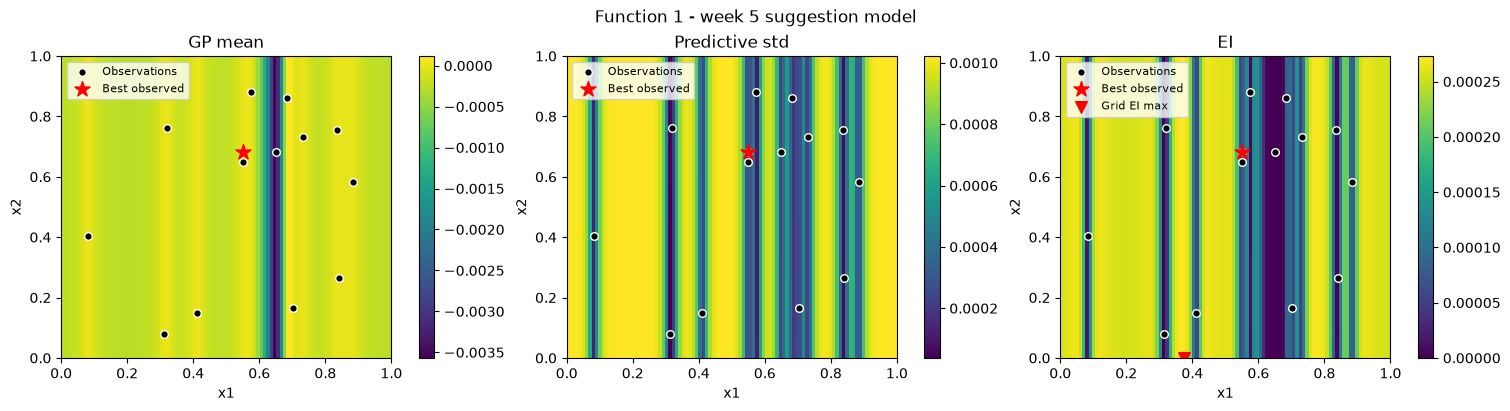

Function 1 - week 5 suggestion model kernel: 1.1**2 * Matern(length_scale=[0.0239, 31.6], nu=1.5) + WhiteKernel(noise_level=0.000621)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


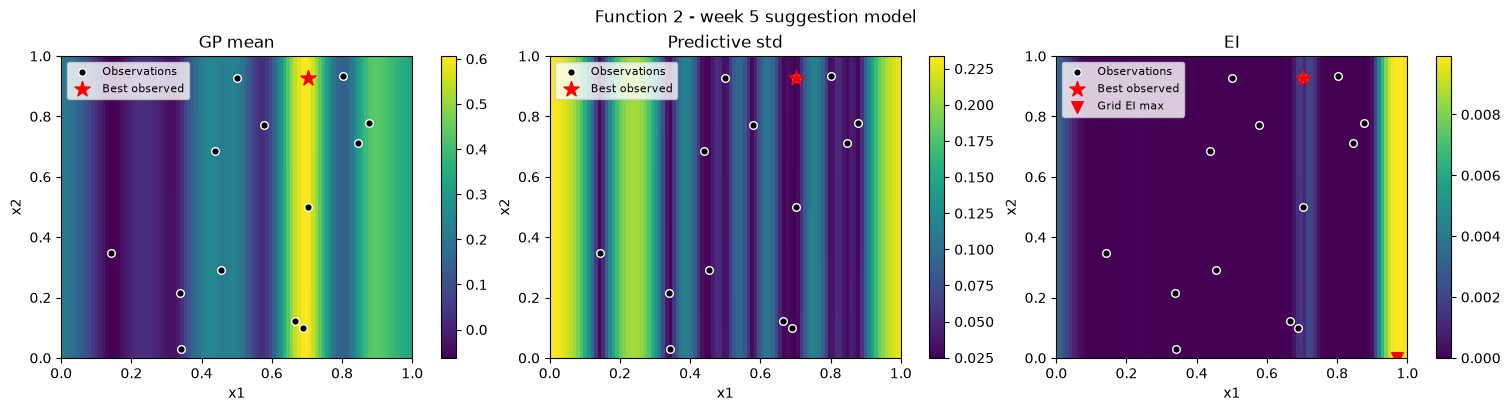

Function 2 - week 5 suggestion model kernel: 1.02**2 * Matern(length_scale=[0.0778, 31.6], nu=1.5) + WhiteKernel(noise_level=0.00718)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


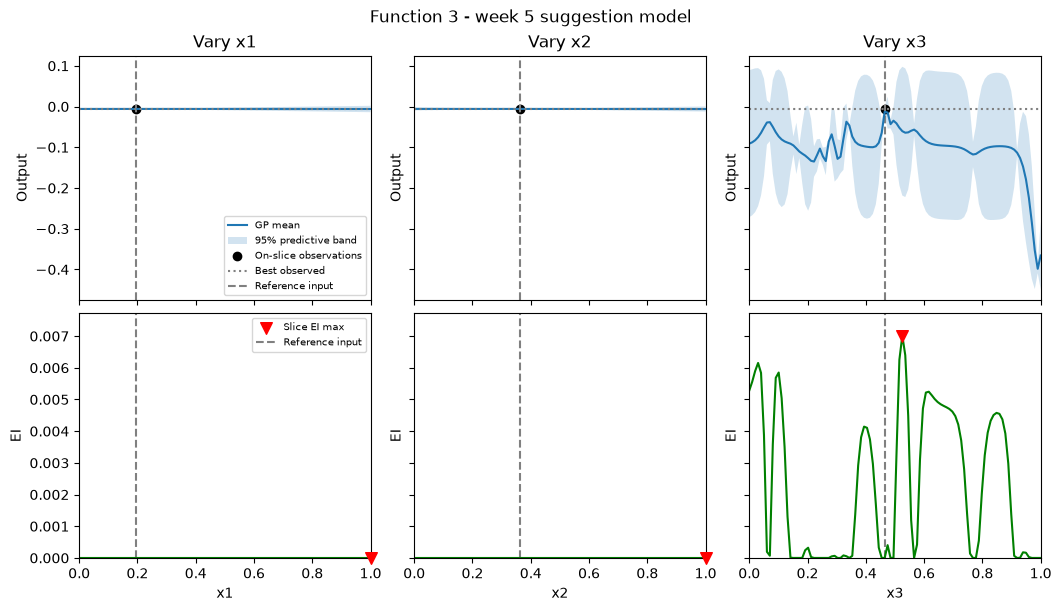

Function 3 - week 5 suggestion model kernel: 1.14**2 * Matern(length_scale=[31.6, 31.6, 0.028], nu=1.5) + WhiteKernel(noise_level=9.63e-07)



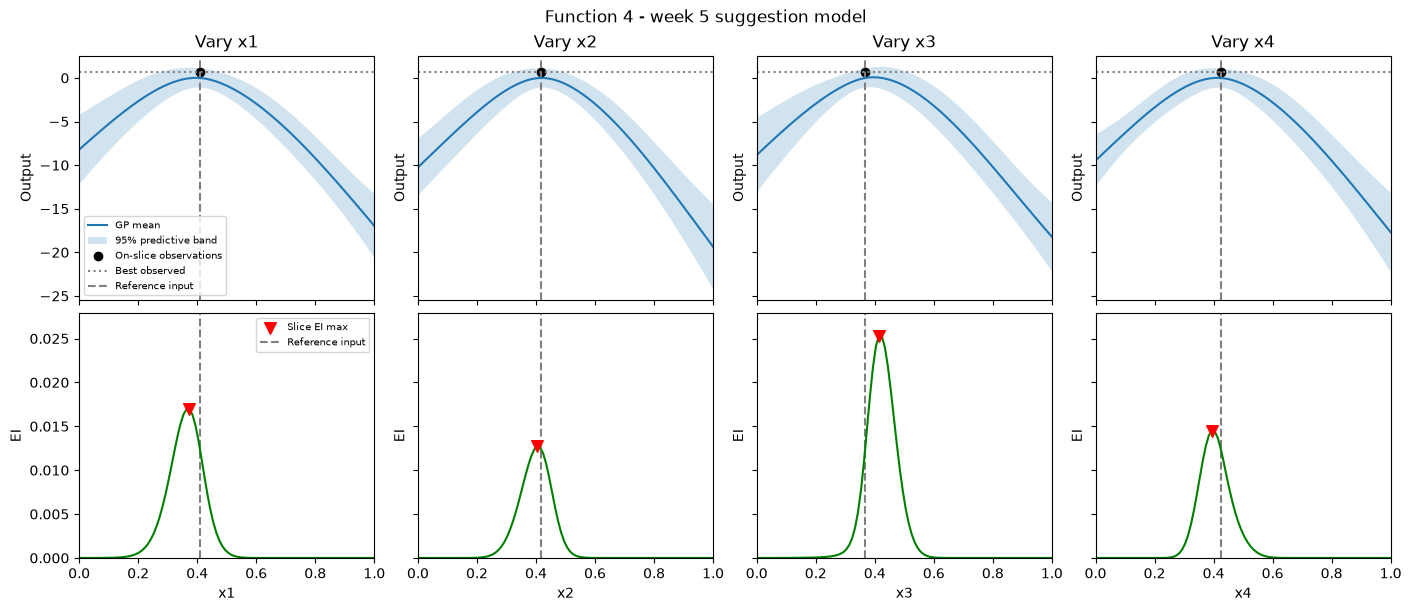

Function 4 - week 5 suggestion model kernel: 4.71**2 * Matern(length_scale=[3.48, 3.11, 3.3, 3.3], nu=1.5) + WhiteKernel(noise_level=0.00286)



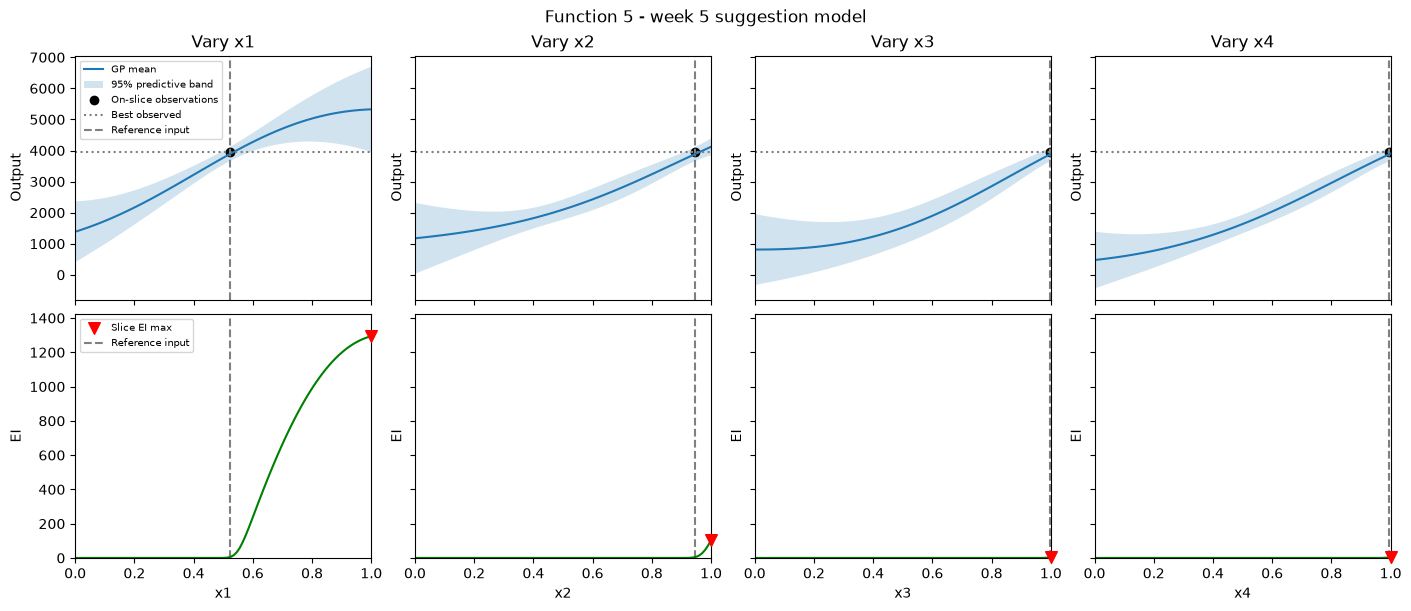

Function 5 - week 5 suggestion model kernel: 3.02**2 * RationalQuadratic(alpha=0.861, length_scale=1.07) + WhiteKernel(noise_level=0.00824)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


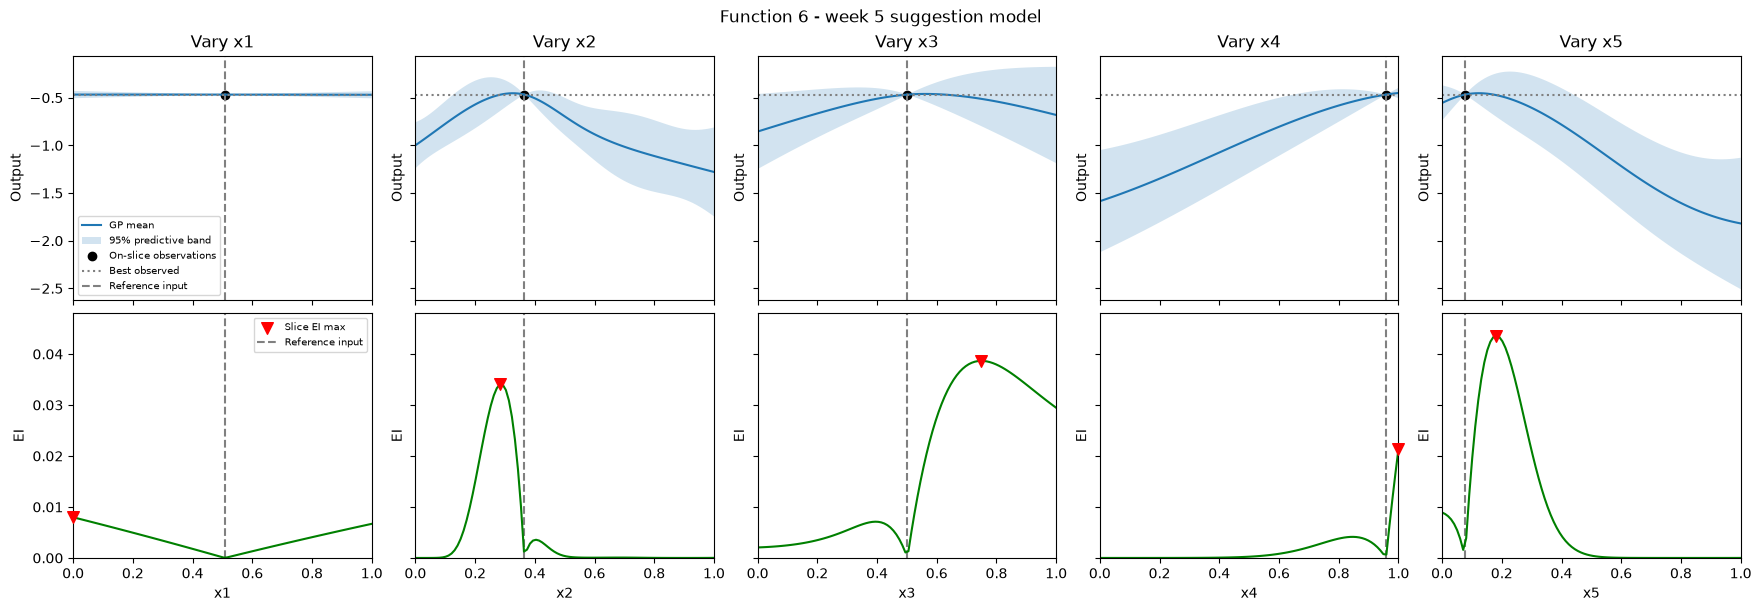

Function 6 - week 5 suggestion model kernel: 1.4**2 * Matern(length_scale=[31.6, 0.619, 1.22, 1.45, 0.64], nu=1.5) + WhiteKernel(noise_level=1e-08)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


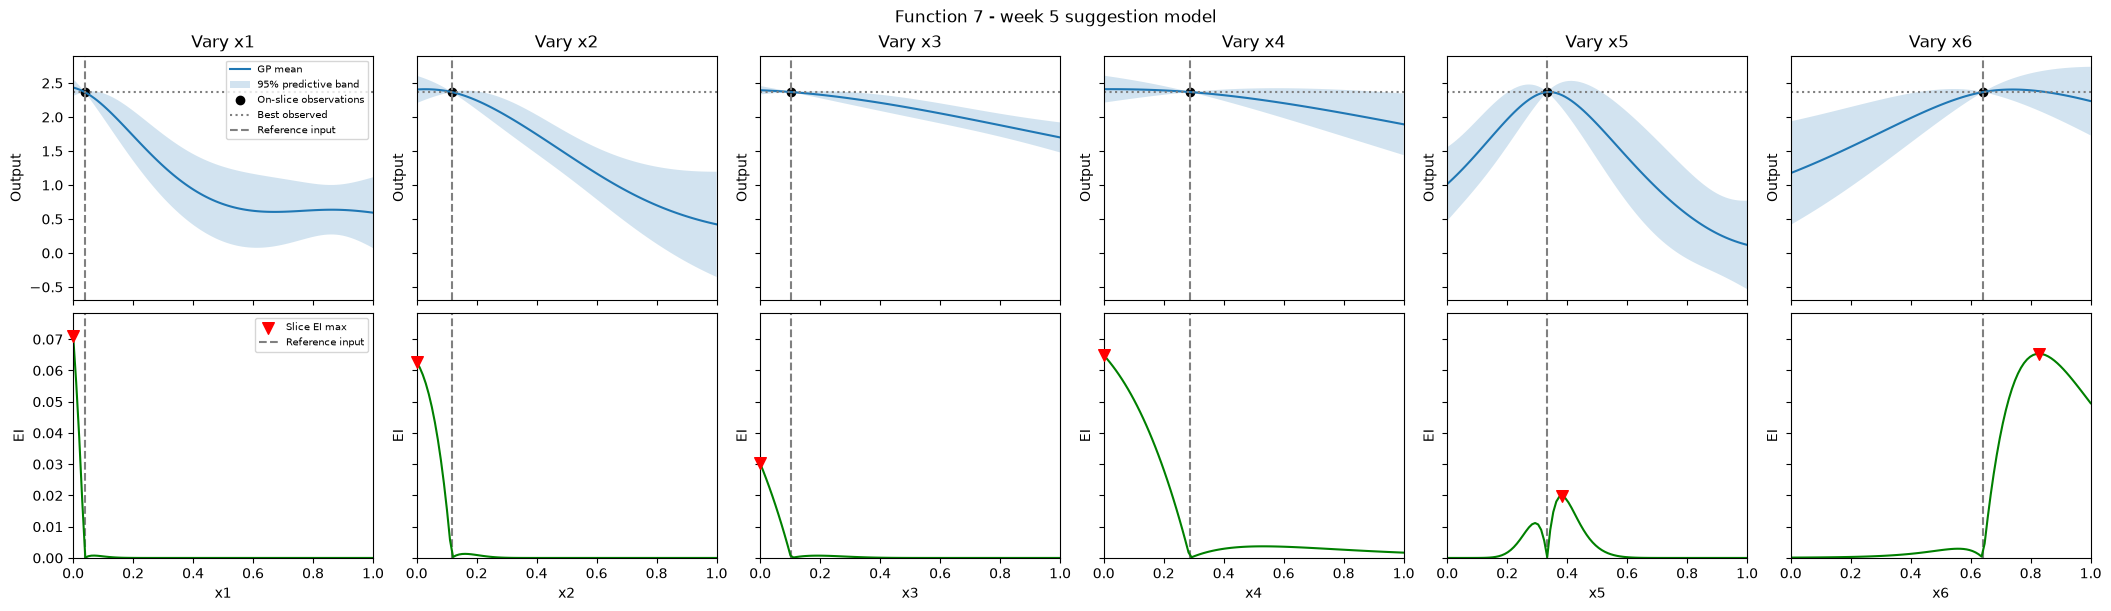

Function 7 - week 5 suggestion model kernel: 1.15**2 * Matern(length_scale=[0.616, 0.966, 2.88, 2.88, 0.484, 1.14], nu=1.5) + WhiteKernel(noise_level=1e-08)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


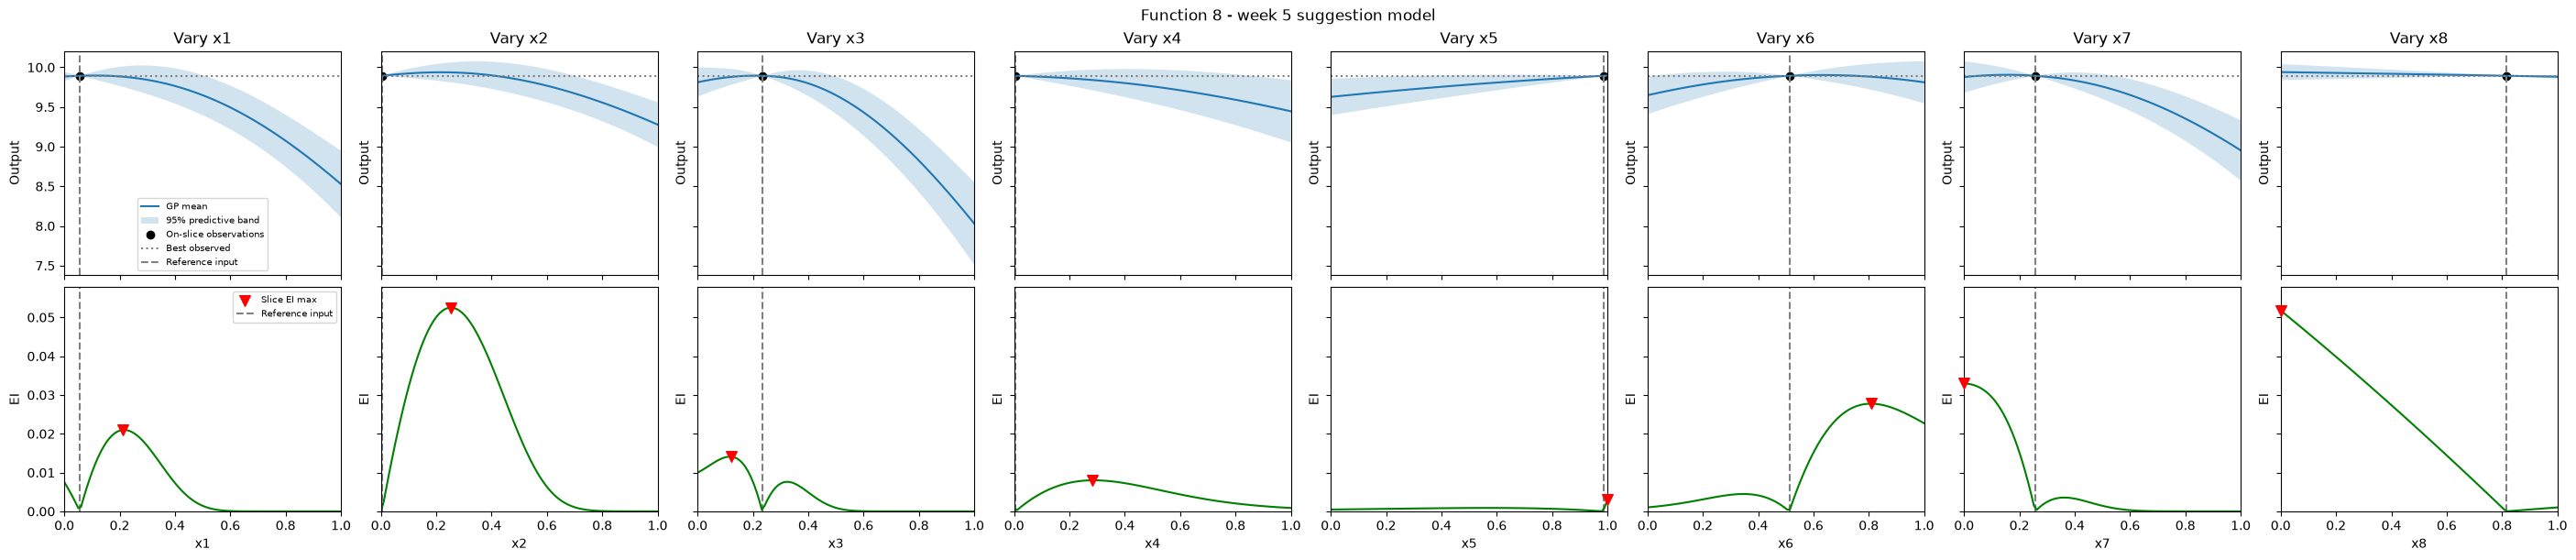

Function 8 - week 5 suggestion model kernel: 6.2**2 * Matern(length_scale=[8.23, 11.2, 5.83, 17.2, 33.9, 12.2, 8.53, 100], nu=1.5) + WhiteKernel(noise_level=1e-08)



In [3]:
plot_function_ids = FUNCTION_IDS
N_CANDIDATES = CONFIG["candidates"]

for function_id in plot_function_ids:
    observations = TRAINING_OBSERVATIONS[function_id]
    kernel = KERNEL_FACTORIES[function_id](observations.dimension, LENGTH_CAPS[function_id])
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(budget=1, candidates=N_CANDIDATES, kernel=kernel, xi=XI_VALUES[function_id]),
    )
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, _ = plot(
        optimizer,
        n=100,
        # candidate=stored_inputs[function_id - 1],
        # expected_mean=stored_predictions["expected_outputs"][function_id - 1],
        # expected_std=stored_predictions["stds"][function_id - 1],
        # expected_ei=stored_predictions["acquisition_scores"][function_id - 1],
    )
    figure.suptitle(f"Function {function_id} - week {WEEKS[-1] + 1} suggestion model")
    display(figure)
    plt.close(figure)
    print(f"Function {function_id} - week {WEEKS[-1]+1} suggestion model kernel: {optimizer._model.kernel_}")
    print()

In [4]:
from bayesian_bbo.submission import format_submission

HEURISTIC_CANDIDATES = {
    1: (0.560000, 0.681526),
    2: (0.692637, 0.926564),
}

candidate_records = []
for function_id in FUNCTION_IDS:
    observations = TRAINING_OBSERVATIONS[function_id]
    kernel = KERNEL_FACTORIES[function_id](observations.dimension, LENGTH_CAPS[function_id])
    optimizer = BayesianOptimizer(observations, OptimisationConfig(
        budget=1, candidates=CONFIG["candidates"], kernel=kernel, xi=XI_VALUES[function_id]))
    if function_id in HEURISTIC_CANDIDATES:
        candidate = np.asarray(HEURISTIC_CANDIDATES[function_id], dtype=float)
        if np.any(np.all(observations.inputs == candidate, axis=1)):
            raise ValueError(f"Function {function_id}: heuristic point has already been evaluated")
        predicted_mean, predicted_std, predicted_ei = optimizer.predict(candidate[None, :])
        mean, std, score = float(predicted_mean[0]), float(predicted_std[0]), float(predicted_ei[0])
        method = "Diagnostic heuristic: vary x1"
    else:
        candidate, mean, std, score = optimizer.suggest_ei_sweep([XI_VALUES[function_id]])[0]
        method = "Optimizer pool EI max"
    candidate_records.append(dict(function_id=function_id, method=method, candidate=tuple(candidate),
                                  submission=format_submission(candidate), alpha=ALPHA_VALUES[function_id],
                                  xi=XI_VALUES[function_id], expected_mean=mean,
                                  expected_std=std, expected_ei=score))
next_candidates = pd.DataFrame(candidate_records)
display(next_candidates)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,function_id,method,candidate,submission,alpha,xi,expected_mean,expected_std,expected_ei
0,1,Diagnostic heuristic: vary x1,"(0.56, 0.681526)",0.560000-0.681526,0.100,0.000093,0.000019,0.000417,0.000132
1,2,Diagnostic heuristic: vary x1,"(0.692637, 0.926564)",0.692637-0.926564,0.100,0.023288,0.605378,0.026900,0.001911
2,3,Optimizer pool EI max,"(0.230343, 0.002456, 0.525039)",0.230343-0.002456-0.525039,0.300,0.024217,-0.060350,0.080565,0.007018
3,4,Optimizer pool EI max,"(0.377087, 0.375898, 0.419683, 0.416322)",0.377087-0.375898-0.419683-0.416322,0.025,0.209010,-0.194162,0.773523,0.027782
4,5,Optimizer pool EI max,"(0.971643, 0.960706, 0.984862, 0.99763)",0.971643-0.960706-0.984862-0.997630,0.100,91.200017,5312.777889,654.553522,1278.673735
5,6,Optimizer pool EI max,"(0.156038, 0.305387, 0.57778, 0.998556, 0.132981)",0.156038-0.305387-0.577780-0.998556-0.132981,0.000,0.000000,-0.433969,0.105457,0.060632
6,7,Optimizer pool EI max,"(0.010124, 0.000341, 0.171968, 0.116063, 0.340...",0.010124-0.000341-0.171968-0.116063-0.340963-0...,0.000,0.000000,2.483301,0.095127,0.120752
7,8,Optimizer pool EI max,"(0.055054, 0.282234, 0.245516, 0.052966, 0.993...",0.055054-0.282234-0.245516-0.052966-0.993069-0...,0.000,0.000000,9.960552,0.083841,0.077560


## 5. Submission format and save week-5 predictions

Display the final F1-F8 selections in six-decimal submission format and save `weekly_updates/week_5/inputs.json` and `predictions.json`, using observations through week 4. Predictions include means, standard deviations, expected best-so-far (incumbent plus EI with xi = 0), configured EI scores and acquisition settings (`xi` and incumbent `best`). The week-5 export replaces only the previous unevaluated week-5 proposal files. Evaluated week-4 inputs, outputs, predictions and observation history remain unchanged.

In [5]:
from bayesian_bbo.data import save_predictions

export_rows = next_candidates.sort_values('function_id').reset_index(drop=True)
if export_rows.function_id.tolist() != list(FUNCTION_IDS):
    raise ValueError('Export requires exactly one candidate per function in FUNCTION_IDS order.')
submission_points = export_rows[['function_id', 'submission']]
with pd.option_context('display.max_colwidth', None):
    display(submission_points)
suggested_points = [[float(value) for value in text.split('-')] for text in export_rows.submission]
if suggested_points != [list(point) for point in export_rows.candidate]:
    raise ValueError('Exported coordinates differ from the points used for predictions.')
best_outputs = [TRAINING_OBSERVATIONS[function_id].best_output for function_id in FUNCTION_IDS]
week_directory = data_root / 'weekly_updates' / f'week_{WEEKS[-1] + 1}'
saved_prediction_paths = save_predictions(
    export_rows.expected_mean.tolist(), suggested_points, export_rows.expected_std.tolist(),
    best_outputs, week_directory,
    acquisition_scores=export_rows.expected_ei.tolist(),
    acquisition_settings=[dict(name='ei', xi=float(xi), best=float(best))
                          for xi, best in zip(export_rows.xi, best_outputs)],
    overwrite=True,
)
saved_prediction_paths

,function_id,submission
0,1,0.560000-0.681526
1,2,0.692637-0.926564
2,3,0.230343-0.002456-0.525039
3,4,0.377087-0.375898-0.419683-0.416322
4,5,0.971643-0.960706-0.984862-0.997630
5,6,0.156038-0.305387-0.577780-0.998556-0.132981
6,7,0.010124-0.000341-0.171968-0.116063-0.340963-0.665352
7,8,0.055054-0.282234-0.245516-0.052966-0.993069-0.708465-0.202215-0.245714


Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_5/inputs.json
Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_5/predictions.json


{'inputs.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_5/inputs.json'),
 'predictions.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_5/predictions.json')}